# 07 Noise floor (Part B6)

Sections 5 and 6 produced point estimates. Here we ask **which differences are larger than the noise**: does the chosen model really beat the baseline, and does it really beat the challenger?

**Method: paired customer-level bootstrap** (`src/bootstrap.py`), 1,000 replicates.
- *Customer clusters.* A customer's loans are correlated, so we resample **customers** with replacement and keep all their loans. Resampling single loans would make intervals too narrow.
- *Paired.* All models are scored on the same resampled set in each replicate, so the difference between two models gets its own interval, which is tighter than comparing two separate intervals.
- *Fold-aware.* Ranking metrics (PR-AUC, ROC-AUC) are computed **within each temporal fold and averaged**, as in Section 5. Pooling out-of-fold scores across folds mixes each fold's offset into the ranking; with pooling, a constant baseline scores ROC 0.44 instead of 0.50. F1 at a fixed threshold and the cedi value add up over loans, so they are pooled.
- 95% percentile intervals.

In [1]:
import sys, warnings; sys.path.append(".."); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
from src.config import set_seed, FIGURES, DATA_PROCESSED
from src.bootstrap import bootstrap, intervals, paired_differences, per_fold, pooled
from src.costs import LoanEconomics, expected_value
from src.validation import regression_errors
set_seed()
econ = LoanEconomics()
feat = pd.read_pickle(DATA_PROCESSED / "features.pkl")
cust = feat.loc[feat.split == "train", ["tbl_loan_id", "customer_id"]]   # Train only: 920 loan IDs also occur in Test
oof = pd.read_pickle(DATA_PROCESSED / "oof_classification.pkl").query("fold >= 0").merge(cust, on="tbl_loan_id", validate="one_to_one")
B = 1000
print(f"{len(oof):,} OOF loans from {oof.customer_id.nunique():,} customers")

39,894 OOF loans from 5,252 customers


## 7.1 Classification: intervals

In [2]:
fns = {"PR-AUC": per_fold(average_precision_score), "ROC-AUC": per_fold(roc_auc_score),
       "F1 @ 0.062": pooled(lambda y, p: f1_score(y, p > econ.threshold)),
       "GHS per 1,000": pooled(lambda y, p: 1000 * expected_value(y, p, econ.threshold, econ) / len(y))}
models = ["logreg", "lgbm_shallow", "baseline"]

def run(d):
    y, f = d.target.to_numpy(), d.fold.to_numpy()
    reps = bootstrap(fns, y, {m: d[m] for m in models}, d.customer_id, f, n_boot=B)
    point = pd.DataFrame({m: {n: fn(y, d[m].to_numpy(), f) for n, fn in fns.items()} for m in models}).T
    return reps, point

reps_all, point_all = run(oof)
reps_sh, point_sh = run(oof[oof.fold >= 3])
ci = pd.concat({"all temporal folds": intervals(reps_all, point_all), "Dec 2022 onward (folds 3-4)": intervals(reps_sh, point_sh)}, names=["scope"])
ci.to_csv(FIGURES.parent / "07_classification_ci.csv")
ci.round(4)

estimate  \
scope                       model        metric                      
all temporal folds          logreg       PR-AUC             0.1428   
                                         ROC-AUC            0.7170   
                                         F1 @ 0.062         0.2017   
                                         GHS per 1,000  19575.8761   
                            lgbm_shallow PR-AUC             0.1302   
                                         ROC-AUC            0.7410   
                                         F1 @ 0.062         0.1850   
                                         GHS per 1,000  19824.4097   
                            baseline     PR-AUC             0.0492   
                                         ROC-AUC            0.5000   
                                         F1 @ 0.062         0.0000   
                                         GHS per 1,000  18350.5038   
Dec 2022 onward (folds 3-4) logreg       PR-AUC             0.2021   
                                         ROC-AUC            0.6375   
                                         F1 @ 0.062         0.2361   
                                         GHS per 1,000  -3586.8031   
                            lgbm_shallow PR-AUC             0.1647   
                                         ROC-AUC            0.6080   
                                         F1 @ 0.062         0.2233   
                                         GHS per 1,000   -919.1955   
                            baseline     PR-AUC             0.1084   
                                         ROC-AUC            0.5000   
                                         F1 @ 0.062         0.0000   
                                         GHS per 1,000 -16586.0974   

                                                             lower       upper  
scope                       model        metric                                 
all temporal folds          logreg       PR-AUC             0.1216      0.1727  
                                         ROC-AUC            0.6922      0.7409  
                                         F1 @ 0.062         0.1780      0.2240  
                                         GHS per 1,000  19072.5604  20065.7020  
                            lgbm_shallow PR-AUC             0.1124      0.1590  
                                         ROC-AUC            0.7220      0.7577  
                                         F1 @ 0.062         0.1666      0.2033  
                                         GHS per 1,000  19378.5627  20250.2989  
                            baseline     PR-AUC             0.0438      0.0556  
                                         ROC-AUC            0.5000      0.5000  
                                         F1 @ 0.062         0.0000      0.0000  
                                         GHS per 1,000  17705.0858  18925.2226  
Dec 2022 onward (folds 3-4) logreg       PR-AUC             0.1675      0.2504  
                                         ROC-AUC            0.5987      0.6791  
                                         F1 @ 0.062         0.2028      0.2675  
                                         GHS per 1,000  -7590.1958   -185.2076  
                            lgbm_shallow PR-AUC             0.1385      0.2067  
                                         ROC-AUC            0.5724      0.6432  
                                         F1 @ 0.062         0.1953      0.2541  
                                         GHS per 1,000  -3692.5326   1640.5516  
                            baseline     PR-AUC             0.0931      0.1244  
                                         ROC-AUC            0.5000      0.5000  
                                         F1 @ 0.062         0.0000      0.0000  
                                         GHS per 1,000 -22248.7788 -11175.7869

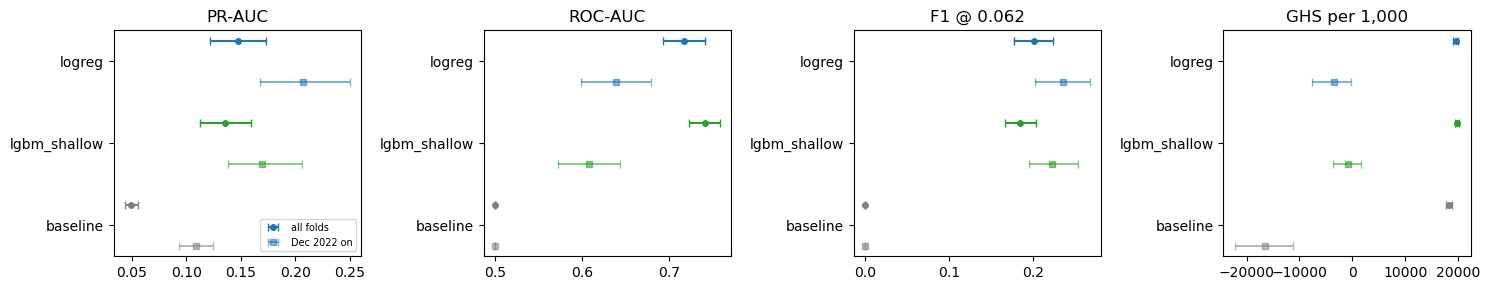

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, metric in zip(axes, fns):
    for k, (scope, reps) in enumerate([("all folds", reps_all), ("Dec 2022 on", reps_sh)]):
        for j, m in enumerate(models):
            v = reps.query("model == @m and metric == @metric").value
            lo, hi, mid = v.quantile(.025), v.quantile(.975), v.median()
            yv = j + 0.25 * (k - .5) * 2
            ax.errorbar(mid, yv, xerr=[[mid - lo], [hi - mid]], fmt="o" if k == 0 else "s", ms=4, capsize=3,
                        color=["tab:blue", "tab:green", "0.5"][j], alpha=1 if k == 0 else .55, label=scope if j == 0 else None)
    ax.set_yticks(range(3), models); ax.set_title(metric); ax.invert_yaxis()
axes[0].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(FIGURES / "07_classification_ci.png", dpi=200); plt.show()

## 7.2 Classification: paired differences

In [4]:
diffs = pd.concat({
    ("logreg - baseline", "all folds"): paired_differences(reps_all, "logreg", "baseline"),
    ("logreg - lgbm_shallow", "all folds"): paired_differences(reps_all, "logreg", "lgbm_shallow"),
    ("logreg - baseline", "Dec 2022 on"): paired_differences(reps_sh, "logreg", "baseline"),
    ("logreg - lgbm_shallow", "Dec 2022 on"): paired_differences(reps_sh, "logreg", "lgbm_shallow"),
}, names=["comparison", "scope"])
diffs["verdict"] = np.where(diffs.lower > 0, "logreg better", np.where(diffs.upper < 0, "logreg worse", "not distinguishable"))
diffs.to_csv(FIGURES.parent / "07_paired_differences.csv")
diffs.round(4)

mean      lower  \
comparison            scope       metric                                 
logreg - baseline     all folds   F1 @ 0.062         0.2015     0.1780   
                                  GHS per 1,000   1224.4540   942.4182   
                                  PR-AUC             0.0978     0.0734   
                                  ROC-AUC            0.2168     0.1922   
logreg - lgbm_shallow all folds   F1 @ 0.062         0.0164    -0.0029   
                                  GHS per 1,000   -249.8896  -506.6444   
                                  PR-AUC             0.0116    -0.0050   
                                  ROC-AUC           -0.0240    -0.0420   
logreg - baseline     Dec 2022 on F1 @ 0.062         0.2359     0.2028   
                                  GHS per 1,000  12998.5043  9480.6047   
                                  PR-AUC             0.0998     0.0647   
                                  ROC-AUC            0.1388     0.0987   
logreg - lgbm_shallow Dec 2022 on F1 @ 0.062         0.0125    -0.0096   
                                  GHS per 1,000  -2709.2974 -5288.7626   
                                  PR-AUC             0.0377     0.0080   
                                  ROC-AUC            0.0306    -0.0020   

                                                      upper  share_a_better  \
comparison            scope       metric                                      
logreg - baseline     all folds   F1 @ 0.062         0.2240           1.000   
                                  GHS per 1,000   1505.1623           1.000   
                                  PR-AUC             0.1226           1.000   
                                  ROC-AUC            0.2409           1.000   
logreg - lgbm_shallow all folds   F1 @ 0.062         0.0323           0.957   
                                  GHS per 1,000    -17.8184           0.016   
                                  PR-AUC             0.0281           0.924   
                                  ROC-AUC           -0.0062           0.003   
logreg - baseline     Dec 2022 on F1 @ 0.062         0.2675           1.000   
                                  GHS per 1,000  16702.0689           1.000   
                                  PR-AUC             0.1394           1.000   
                                  ROC-AUC            0.1791           1.000   
logreg - lgbm_shallow Dec 2022 on F1 @ 0.062         0.0353           0.861   
                                  GHS per 1,000   -355.4609           0.016   
                                  PR-AUC             0.0697           0.995   
                                  ROC-AUC            0.0625           0.968   

                                                             verdict  
comparison            scope       metric                              
logreg - baseline     all folds   F1 @ 0.062           logreg better  
                                  GHS per 1,000        logreg better  
                                  PR-AUC               logreg better  
                                  ROC-AUC              logreg better  
logreg - lgbm_shallow all folds   F1 @ 0.062     not distinguishable  
                                  GHS per 1,000         logreg worse  
                                  PR-AUC         not distinguishable  
                                  ROC-AUC               logreg worse  
logreg - baseline     Dec 2022 on F1 @ 0.062           logreg better  
                                  GHS per 1,000        logreg better  
                                  PR-AUC               logreg better  
                                  ROC-AUC              logreg better  
logreg - lgbm_shallow Dec 2022 on F1 @ 0.062     not distinguishable  
                                  GHS per 1,000         logreg worse  
                                  PR-AUC               logreg better  
                                  ROC-AUC        not distinguishable

## 7.3 Regression: intervals

In [5]:
rcust = feat.loc[(feat.split == "train") & (feat.target == 0), ["tbl_loan_id", "customer_id"]]
ro = pd.read_pickle(DATA_PROCESSED / "oof_regression.pkl").query("fold >= 0").merge(rcust, on="tbl_loan_id", validate="one_to_one")
rmodels = ["ridge", "lgbm", "persistence"]
rfns = {"RMSE (log)": pooled(lambda y, p: regression_errors(y, p)["rmse_log"]),
        "MAE (KES)": pooled(lambda y, p: regression_errors(y, p)["mae_amt"]),
        "within 25%": pooled(lambda y, p: regression_errors(y, p)["within_25pct"])}
def rrun(d):
    y, f = d.log_amount_target.to_numpy(), d.fold.to_numpy()
    reps = bootstrap(rfns, y, {m: d[m] for m in rmodels}, d.customer_id, f, n_boot=B)
    point = pd.DataFrame({m: {n: fn(y, d[m].to_numpy(), f) for n, fn in rfns.items()} for m in rmodels}).T
    return reps, point
rreps_all, rpoint_all = rrun(ro)
rreps_sh, rpoint_sh = rrun(ro[ro.fold >= 3])
display(pd.concat({"all folds": intervals(rreps_all, rpoint_all), "Dec 2022 on": intervals(rreps_sh, rpoint_sh)}, names=["scope"]).round(3))
rd = pd.concat({(f"ridge - {b}", s): paired_differences(r, "ridge", b) for b in ["lgbm", "persistence"]
                for s, r in [("all folds", rreps_all), ("Dec 2022 on", rreps_sh)]}, names=["comparison", "scope"])
rd.round(3)

estimate      lower      upper
scope       model       metric                                     
all folds   ridge       RMSE (log)      0.759      0.745      0.772
                        MAE (KES)    5907.178   5348.590   6487.258
                        within 25%      0.338      0.331      0.346
            lgbm        RMSE (log)      0.761      0.746      0.777
                        MAE (KES)    6488.878   5773.709   7253.215
                        within 25%      0.345      0.338      0.352
            persistence RMSE (log)      0.811      0.793      0.830
                        MAE (KES)    6216.409   5407.545   7116.507
                        within 25%      0.382      0.373      0.390
Dec 2022 on ridge       RMSE (log)      0.654      0.597      0.718
                        MAE (KES)   22649.769  16839.629  29332.688
                        within 25%      0.430      0.405      0.452
            lgbm        RMSE (log)      0.792      0.686      0.910
                        MAE (KES)   31184.400  23669.909  40089.899
                        within 25%      0.470      0.442      0.496
            persistence RMSE (log)      0.846      0.781      0.916
                        MAE (KES)   23006.222  16639.944  30609.748
                        within 25%      0.484      0.456      0.511

mean      lower     upper  \
comparison          scope       metric                                      
ridge - lgbm        all folds   MAE (KES)   -586.074   -904.579  -295.982   
                                RMSE (log)    -0.002     -0.010     0.004   
                                within 25%    -0.007     -0.012    -0.002   
                    Dec 2022 on MAE (KES)  -8547.348 -12454.019 -4959.933   
                                RMSE (log)    -0.136     -0.206    -0.076   
                                within 25%    -0.039     -0.073    -0.006   
ridge - persistence all folds   MAE (KES)   -307.618   -844.012   102.109   
                                RMSE (log)    -0.053     -0.063    -0.044   
                                within 25%    -0.044     -0.050    -0.038   
                    Dec 2022 on MAE (KES)   -359.352  -2654.141  1759.044   
                                RMSE (log)    -0.192     -0.243    -0.142   
                                within 25%    -0.053     -0.089    -0.021   

                                            share_a_better  
comparison          scope       metric                      
ridge - lgbm        all folds   MAE (KES)            0.000  
                                RMSE (log)           0.267  
                                within 25%           0.002  
                    Dec 2022 on MAE (KES)            0.000  
                                RMSE (log)           0.000  
                                within 25%           0.013  
ridge - persistence all folds   MAE (KES)            0.074  
                                RMSE (log)           0.000  
                                within 25%           0.000  
                    Dec 2022 on MAE (KES)            0.373  
                                RMSE (log)           0.000  
                                within 25%           0.000

For RMSE and MAE a *negative* difference means ridge is better; for *within 25%* a positive one does.

## 7.4 Verdict

**Does the chosen classifier beat the baseline?** Yes, clearly, on every metric and in both scopes. Every bootstrap replicate favours logistic regression over approving everyone, including in cedis. In the post-2022 regime, PR-AUC roughly doubles the base rate and the model avoids most of the loss from approving everyone, even though its ROC there is only about 0.6.

**Does it beat shallow LightGBM?** It depends on the metric, and the bootstrap makes that trade-off explicit:
- *All folds:* PR-AUC and F1 are **not distinguishable** (both difference intervals include zero). Shallow LightGBM is significantly better on ROC-AUC (by 0.024) and earns significantly, if narrowly, more at the 0.062 threshold (about 250 GHS per 1,000 applications, interval 18 to 507).
- *Dec 2022 onward:* logistic regression is **significantly better on PR-AUC** (+0.038, interval 0.008 to 0.070), and ROC is not distinguishable. Yet LightGBM earns about 2,700 GHS more per 1,000 there, because its over-spread probabilities push more borrowers over the 0.062 threshold (it declines 55% against 36%). That gain comes from where the threshold falls, not from better ranking, and recalibration would change it for both models.

**Consequence for the model choice.** Neither model dominates. We keep **logistic regression**: it ranks the riskiest borrowers significantly better in the regime that most resembles Ghana, it is transparent (reason codes, Section 9), simple to audit against Act 843 and the BoG Directive (Part D), and cheap to recalibrate. We report shallow LightGBM as the alternative with better overall ROC and slightly higher cedi value at a fixed threshold, and we do not claim the linear model is more accurate overall.

**Regression.** Pooled, ridge and LightGBM tie on log RMSE; ridge is significantly better on MAE in KES (by about 590) and LightGBM slightly better at landing within 25%. After Dec 2022 ridge is significantly better on log RMSE (by 0.14) and MAE (by about 8,500 KES), confirming that the trees overfit the boom. Against the persistence rule, ridge is significantly better on log RMSE, the rule is significantly better at landing within 25%, and MAE in KES is not distinguishable. The learned model's value over the rule is in avoiding large misses, not in typical accuracy.

**Width of the noise floor.** Fold-averaged PR-AUC intervals are about ±0.025 overall and wider after Dec 2022 (only 291 test defaults). Differences between candidate models in Sections 5 and 6 that are smaller than about 0.02 PR-AUC should not be reported as improvements.